In [1]:
import torch
import os
import logging
import timm
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts, ReduceLROnPlateau
from src.dataset import FundusDataset, get_transform, get_soft_balanced_sampler
from src.loss import FocalLoss
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM
from src.optimizer import optimizer, optimizer_update
from src.training import training

def seed(seed):
    import random
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(7)

g = torch.Generator()
g.manual_seed(7)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
json_dir = os.path.join(data_dir, "data_info.json")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
log_dir = os.path.join(eval_dir, "logs")

train_transform, valid_transform = get_transform(380)

train_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=1, transform=train_transform)
valid_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=2,transform=valid_transform)

sampler, class_weights = get_soft_balanced_sampler(train_dataset, softness=0) # softness=0 means perfect class balance

train_loader = DataLoader(
    train_dataset,
    batch_size=20,
    sampler=sampler,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=20,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)

checkpoint = torch.load("D:/DeepLearning/Evaluation/EfficientNet-B4/APTOS-2019/checkpoints/epoch53_validF1_0.7368.pth")
state = checkpoint.get("model_state", checkpoint.get("state_dict", checkpoint))
filtered = {}
for k, v in state.items():
    if any(p in k for p in ["conv_head", "blocks.5", "blocks.6", "bn2"]):
        continue
    filtered[k] = v
backbone.load_state_dict(filtered, strict=False)

def kaiming_init(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        if getattr(m, "weight", None) is not None: nn.init.ones_(m.weight)
        if getattr(m, "bias", None) is not None: nn.init.zeros_(m.bias)
        if getattr(m, "running_mean", None) is not None: m.running_mean.zero_()
        if getattr(m, "running_var", None) is not None: m.running_var.fill_(1.0)

# backbone.cbam.apply(kaiming_init)
for i in range(5, len(backbone.blocks)):
    backbone.blocks[i].apply(kaiming_init)
backbone.conv_head.apply(kaiming_init)
backbone.bn2.apply(kaiming_init)

model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model.freeze(block_index=6, freeze_stem=True)
model.freeze_cbam()
model = model.to(device)

alpha_raw = torch.tensor([class_weights[i] for i in sorted(class_weights.keys())], dtype=torch.float)
alpha_smooth = torch.sqrt(alpha_raw)
alpha_tensor = alpha_smooth / alpha_smooth.mean() # normalise with mean so that tensor's average is 1
alpha_tensor = alpha_tensor.to(device)
criterion = FocalLoss(alpha=alpha_tensor, gamma=2)

for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

log_file = os.path.join(log_dir, 'training_log.txt')
logging.basicConfig(
    filename=log_file,
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filemode='a'  # use 'a' to append to existing logs
)

best_checkpoint_path = os.path.join(chkpt_dir, "best_checkpoint.pth")
training_record = {
        "train_loss": [],
        "valid_loss": [],
        "train_f1": [],
        "valid_f1": [],
    }

classifier_optimizer = optimizer(model=model, lr=5e-4, weight_decay=1e-4)
model.unfreeze(block_index=6, unfreeze_stem=False)
model.unfreeze(block_index=5, unfreeze_stem=False)
optimizer = optimizer_update(model=model, optimizer=classifier_optimizer, lr=1e-4, weight_decay=1e-4)
model.unfreeze_cbam()
optimizer = optimizer_update(model=model, optimizer=optimizer, lr=5e-5, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer=optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-6)

training_record = training(model, train_loader, valid_loader, criterion, classifier_optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=5, best_validation_f1=-1.0, start_epoch=0)

model.unfreeze(block_index=4, unfreeze_stem=False)
model.unfreeze(block_index=3, unfreeze_stem=False)
checkpoint = torch.load(best_checkpoint_path)
model.load_state_dict(checkpoint["model_state"])
best_validation_f1 = checkpoint["best_valid_f1"]
optimizer = optimizer_update(model=model, optimizer=optimizer, lr=1e-5, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer=optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-6)

training_record = training(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=15, best_validation_f1=best_validation_f1, start_epoch=5)

model.unfreeze(block_index=2, unfreeze_stem=False)
model.unfreeze(block_index=1, unfreeze_stem=False)
model.unfreeze(block_index=0, unfreeze_stem=True)
checkpoint = torch.load(best_checkpoint_path)
model.load_state_dict(checkpoint["model_state"])
best_validation_f1 = checkpoint["best_valid_f1"]
optimizer = optimizer_update(model=model, optimizer=optimizer, lr=1e-6, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer=optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7)

training_record = training(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=25, best_validation_f1=best_validation_f1, start_epoch=15)

Training: Epoch 1/5:   0%|          | 0/131 [00:00<?, ?it/s]

Validation::   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/5:
Train Loss: 0.1609, Train Accuracy: 0.5866, Train F1: 0.5646
Valid Loss: 0.1529, Valid Accuracy: 0.7500, Valid F1: 0.7442
best model saved to:  D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT\checkpointspaper\epoch1_validF1_0.7442.pth


Training: Epoch 2/5:   0%|          | 0/131 [00:00<?, ?it/s]

Validation::   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 2/5:
Train Loss: 0.1460, Train Accuracy: 0.6758, Train F1: 0.6716
Valid Loss: 0.1939, Valid Accuracy: 0.5400, Valid F1: 0.4232


... (65 outputs left out)

Epoch 24/25:
Train Loss: 0.0838, Train Accuracy: 0.8436, Train F1: 0.8430
Valid Loss: 0.2118, Valid Accuracy: 0.6750, Valid F1: 0.6635


Training: Epoch 25/25:   0%|          | 0/131 [00:00<?, ?it/s]

Validation::   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 25/25:
Train Loss: 0.0757, Train Accuracy: 0.8678, Train F1: 0.8670
Valid Loss: 0.2095, Valid Accuracy: 0.7250, Valid F1: 0.7219


Validation classification report: {'Normal': {'precision': 0.8314606741573034, 'recall': 0.74, 'f1-score': 0.783068783068783, 'support': 100.0}, 'Thickened': {'precision': 0.7657657657657657, 'recall': 0.85, 'f1-score': 0.8056872037914692, 'support': 100.0}, 'accuracy': 0.795, 'macro avg': {'precision': 0.7986132199615346, 'recall': 0.7949999999999999, 'f1-score': 0.794377993430126, 'support': 200.0}, 'weighted avg': {'precision': 0.7986132199615347, 'recall': 0.795, 'f1-score': 0.7943779934301262, 'support': 200.0}}
Validation AU-ROC: 0.8324  AU-PRC: 0.8263
Test classification report: {'Normal': {'precision': 0.7755102040816326, 'recall': 0.76, 'f1-score': 0.7676767676767676, 'support': 50.0}, 'Thickened': {'precision': 0.7647058823529411, 'recall': 0.78, 'f1-score': 0.7722772277227723, 'support': 50.0}, 'accuracy': 0.77, 'macro avg': {'precision': 0.7701080432172869, 'recall': 0.77, 'f1-score': 0.7699769976997699, 'support': 100.0}, 'weighted avg': {'precision': 0.770108043217287, 'r

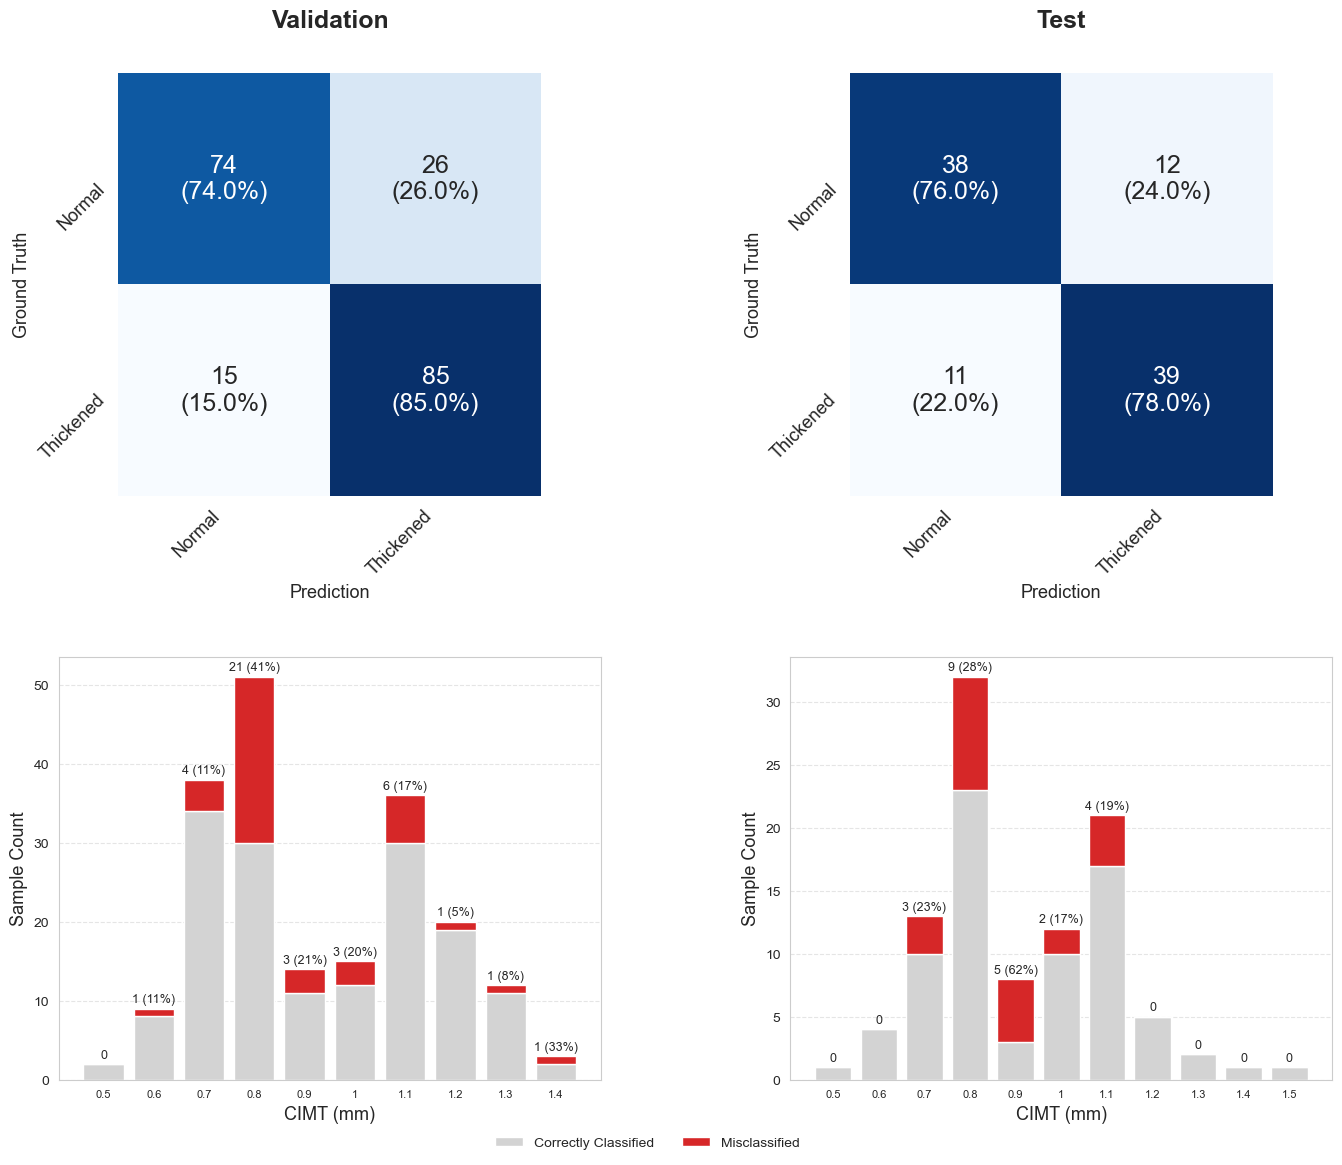

In [10]:
import torch
import timm
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM

def seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(3)

g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")
os.makedirs(result_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform, valid_transform = get_transform(380)

class_names = ['Normal', 'Thickened']

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model = model.to(device)
checkpoint = torch.load(os.path.join(chkpt_dir, "epoch24_validF1_0.7944.pth"))
model.load_state_dict(checkpoint["model_state"])
model.eval()


def evaluate_group(group_value):
    dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=group_value, transform=valid_transform)
    loader = DataLoader(
        dataset,
        batch_size=40,
        shuffle=False,
        num_workers=8,
        pin_memory=True,
        prefetch_factor=2,
        generator=g,
    )

    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for left_images, right_images, labels in loader:
            left_images = left_images.to(device, non_blocking=True)
            right_images = right_images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(left_images, right_images)
            _, preds = torch.max(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs[:, 1].cpu().numpy())

    ordered_rows = dataset.dataframe.loc[dataset.indices]
    thickness_values = ordered_rows["thickness"].tolist()
    assert len(thickness_values) == len(all_labels), (
        f"Mismatch: {len(thickness_values)} thickness values vs {len(all_labels)} predictions."
    )

    report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)
    auroc = roc_auc_score(all_labels, all_probs)
    auprc = average_precision_score(all_labels, all_probs)

    return {
        "preds": np.array(all_preds),
        "labels": np.array(all_labels),
        "probs": np.array(all_probs),
        "thickness": np.array(thickness_values),
        "report": report,
        "auroc": auroc,
        "auprc": auprc,
    }


valid_results = evaluate_group(group_value=2)
test_results = evaluate_group(group_value=3)

print("Validation classification report:", valid_results["report"])
print(f"Validation AU-ROC: {valid_results['auroc']:.4f}  AU-PRC: {valid_results['auprc']:.4f}")
print("Test classification report:", test_results["report"])
print(f"Test AU-ROC: {test_results['auroc']:.4f}  AU-PRC: {test_results['auprc']:.4f}")


def build_thickness_summary(labels, preds, thickness):
    df = pd.DataFrame({"thickness": thickness, "true_label": labels, "pred_label": preds})
    df["correct"] = df["true_label"] == df["pred_label"]
    summary = df.groupby("thickness", observed=True).agg(
        n_total=("correct", "count"),
        n_misclassified=("correct", lambda x: int((~x).sum()))
    ).reset_index()
    summary["n_correct"] = summary["n_total"] - summary["n_misclassified"]
    summary["pct_misclassified"] = np.where(
        summary["n_total"] > 0,
        summary["n_misclassified"] / summary["n_total"] * 100,
        0.0
    )
    return summary.sort_values("thickness").reset_index(drop=True)


valid_summary = build_thickness_summary(valid_results["labels"], valid_results["preds"], valid_results["thickness"])
test_summary = build_thickness_summary(test_results["labels"], test_results["preds"], test_results["thickness"])

valid_summary.to_csv(os.path.join(result_dir, "misclassification_by_thickness_valid.csv"), index=False)
test_summary.to_csv(os.path.join(result_dir, "misclassification_by_thickness_test.csv"), index=False)

# ------------------------------------------------------------------
# Combined 2x2 figure
# ------------------------------------------------------------------

def plot_cm(ax, labels, preds, class_labels):
    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    annot = np.empty_like(cm).astype(object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)"

    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        ax=ax,
        square=True,
        annot_kws={"fontsize": 18},
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=13)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=45, ha="right", va="top", fontsize=13)

    ax.set_xlabel("Prediction", fontsize=13)
    ax.set_ylabel("Ground Truth", fontsize=13)


def plot_thickness_bar(ax, summary):
    x = np.arange(len(summary))
    ax.bar(x, summary["n_correct"], color="lightgray", label="Correctly Classified")
    ax.bar(x, summary["n_misclassified"], bottom=summary["n_correct"], color="#D62728", label="Misclassified")

    for i, (n_total, n_mis, pct) in enumerate(zip(summary["n_total"], summary["n_misclassified"], summary["pct_misclassified"])):
        if n_total > 0:
            label = f"{int(n_mis)} ({pct:.0f}%)" if n_mis > 0 else "0"
            ax.text(i, n_total + max(summary["n_total"]) * 0.008, label,
                     ha="center", va="bottom", fontsize=9, rotation=0)

    ax.set_xticks(x)
    n_labels = len(summary)
    step = max(1, n_labels // 15)
    thinned_labels = [f"{v:g}" if i % step == 0 else "" for i, v in enumerate(summary["thickness"])]
    ax.set_xticklabels(thinned_labels, rotation=0, ha="center", fontsize=8)

    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.grid(axis="x", visible=False)

    ax.set_xlabel("CIMT (mm)", fontsize=13)
    ax.set_ylabel("Sample Count", fontsize=13)


fig, axes = plt.subplots(2, 2, figsize=(14, 12))

plot_cm(axes[0, 0], valid_results["labels"], valid_results["preds"], class_names)
plot_cm(axes[0, 1], test_results["labels"], test_results["preds"], class_names)

plot_thickness_bar(axes[1, 0], valid_summary)
plot_thickness_bar(axes[1, 1], test_summary)

# Increased vertical gap between rows (confusion matrices vs bar charts)
plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])
fig.subplots_adjust(hspace=0.38, wspace=0.35)

fig.canvas.draw()
pos_left = axes[0, 0].get_position()
pos_right = axes[0, 1].get_position()

# Column headers moved close to the matrices
header_y = pos_left.y1 + 0.034
fig.text((pos_left.x0 + pos_left.x1) / 2, header_y, "Validation",
          ha="center", va="bottom", fontsize=18, fontweight="bold")
fig.text((pos_right.x0 + pos_right.x1) / 2, header_y, "Test",
          ha="center", va="bottom", fontsize=18, fontweight="bold")

# Legend for the bar chart row
handles, legend_labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.03), frameon=False)

plt.savefig(os.path.join(result_dir, "combined_valid_test_summary.pdf"), bbox_inches="tight")
plt.show()

Validation classification report: {'Normal': {'precision': 0.8314606741573034, 'recall': 0.74, 'f1-score': 0.783068783068783, 'support': 100.0}, 'Thickened': {'precision': 0.7657657657657657, 'recall': 0.85, 'f1-score': 0.8056872037914692, 'support': 100.0}, 'accuracy': 0.795, 'macro avg': {'precision': 0.7986132199615346, 'recall': 0.7949999999999999, 'f1-score': 0.794377993430126, 'support': 200.0}, 'weighted avg': {'precision': 0.7986132199615347, 'recall': 0.795, 'f1-score': 0.7943779934301262, 'support': 200.0}}
Validation AU-ROC: 0.8324  AU-PRC: 0.8263
Test classification report: {'Normal': {'precision': 0.7755102040816326, 'recall': 0.76, 'f1-score': 0.7676767676767676, 'support': 50.0}, 'Thickened': {'precision': 0.7647058823529411, 'recall': 0.78, 'f1-score': 0.7722772277227723, 'support': 50.0}, 'accuracy': 0.77, 'macro avg': {'precision': 0.7701080432172869, 'recall': 0.77, 'f1-score': 0.7699769976997699, 'support': 100.0}, 'weighted avg': {'precision': 0.770108043217287, 'r

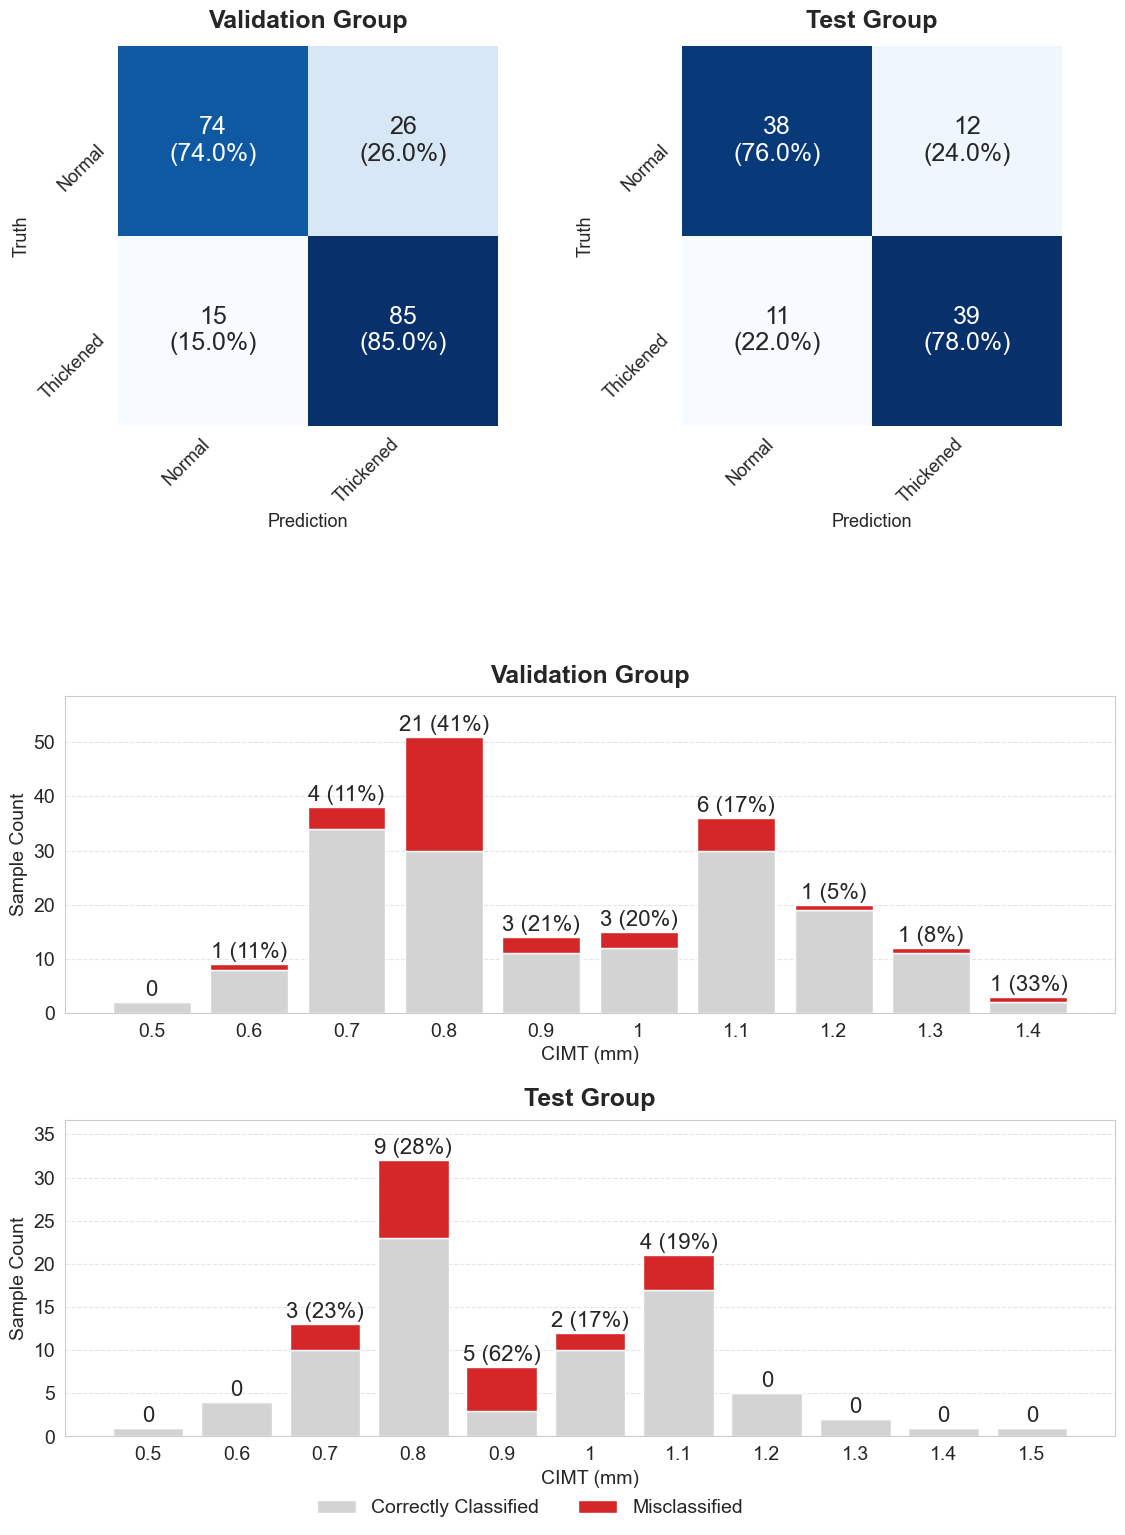

In [9]:
import torch
import timm
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM

def seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(3)

g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")
os.makedirs(result_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform, valid_transform = get_transform(380)

class_names = ['Normal', 'Thickened']

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model = model.to(device)
checkpoint = torch.load(os.path.join(chkpt_dir, "epoch24_validF1_0.7944.pth"))
model.load_state_dict(checkpoint["model_state"])
model.eval()


def evaluate_group(group_value):
    dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=group_value, transform=valid_transform)
    loader = DataLoader(
        dataset,
        batch_size=40,
        shuffle=False,
        num_workers=8,
        pin_memory=True,
        prefetch_factor=2,
        generator=g,
    )

    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for left_images, right_images, labels in loader:
            left_images = left_images.to(device, non_blocking=True)
            right_images = right_images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(left_images, right_images)
            _, preds = torch.max(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs[:, 1].cpu().numpy())

    ordered_rows = dataset.dataframe.loc[dataset.indices]
    thickness_values = ordered_rows["thickness"].tolist()
    assert len(thickness_values) == len(all_labels), (
        f"Mismatch: {len(thickness_values)} thickness values vs {len(all_labels)} predictions."
    )

    report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)
    auroc = roc_auc_score(all_labels, all_probs)
    auprc = average_precision_score(all_labels, all_probs)

    return {
        "preds": np.array(all_preds),
        "labels": np.array(all_labels),
        "probs": np.array(all_probs),
        "thickness": np.array(thickness_values),
        "report": report,
        "auroc": auroc,
        "auprc": auprc,
    }


valid_results = evaluate_group(group_value=2)
test_results = evaluate_group(group_value=3)

print("Validation classification report:", valid_results["report"])
print(f"Validation AU-ROC: {valid_results['auroc']:.4f}  AU-PRC: {valid_results['auprc']:.4f}")
print("Test classification report:", test_results["report"])
print(f"Test AU-ROC: {test_results['auroc']:.4f}  AU-PRC: {test_results['auprc']:.4f}")


def build_thickness_summary(labels, preds, thickness):
    df = pd.DataFrame({"thickness": thickness, "true_label": labels, "pred_label": preds})
    df["correct"] = df["true_label"] == df["pred_label"]
    summary = df.groupby("thickness", observed=True).agg(
        n_total=("correct", "count"),
        n_misclassified=("correct", lambda x: int((~x).sum()))
    ).reset_index()
    summary["n_correct"] = summary["n_total"] - summary["n_misclassified"]
    summary["pct_misclassified"] = np.where(
        summary["n_total"] > 0,
        summary["n_misclassified"] / summary["n_total"] * 100,
        0.0
    )
    return summary.sort_values("thickness").reset_index(drop=True)


valid_summary = build_thickness_summary(valid_results["labels"], valid_results["preds"], valid_results["thickness"])
test_summary = build_thickness_summary(test_results["labels"], test_results["preds"], test_results["thickness"])

valid_summary.to_csv(os.path.join(result_dir, "misclassification_by_thickness_valid.csv"), index=False)
test_summary.to_csv(os.path.join(result_dir, "misclassification_by_thickness_test.csv"), index=False)

# ------------------------------------------------------------------
# Combined figure: 2 confusion matrices (top row) + 2 stacked bar charts (below)
# ------------------------------------------------------------------

def plot_cm(ax, labels, preds, class_labels):
    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    annot = np.empty_like(cm).astype(object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)"

    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        ax=ax,
        square=True,
        annot_kws={"fontsize": 18},
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=13)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=45, ha="right", va="top", fontsize=13)

    ax.set_xlabel("Prediction", fontsize=13)
    ax.set_ylabel("Truth", fontsize=13)


def plot_thickness_bar(ax, summary, title=None, fontsize=14, label_fontsize=16, ytick_fontsize=14):
    x = np.arange(len(summary))
    ax.bar(x, summary["n_correct"], color="lightgray", label="Correctly Classified")
    ax.bar(x, summary["n_misclassified"], bottom=summary["n_correct"], color="#D62728", label="Misclassified")

    max_total = max(summary["n_total"])
    for i, (n_total, n_mis, pct) in enumerate(zip(summary["n_total"], summary["n_misclassified"], summary["pct_misclassified"])):
        if n_total > 0:
            label = f"{int(n_mis)} ({pct:.0f}%)" if n_mis > 0 else "0"
            ax.text(i, n_total + max_total * 0.008, label,
                     ha="center", va="bottom", fontsize=label_fontsize, rotation=0)

    # Extra headroom above the tallest bar so labels aren't clipped by the axis.
    # Scales with label_fontsize so bigger text automatically gets more room.
    headroom = 0.05 + label_fontsize * 0.006
    ax.set_ylim(0, max_total * (1 + headroom))

    ax.set_xticks(x)
    n_labels = len(summary)
    step = max(1, n_labels // 30)  # more labels can fit now that the bar chart is full-width
    thinned_labels = [f"{v:g}" if i % step == 0 else "" for i, v in enumerate(summary["thickness"])]
    ax.set_xticklabels(thinned_labels, rotation=0, ha="center", fontsize=14)

    # y-axis tick numbers (the sample-count values running up the left side)
    ax.tick_params(axis="y", labelsize=ytick_fontsize)

    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.grid(axis="x", visible=False)

    ax.set_xlabel("CIMT (mm)", fontsize=14)
    ax.set_ylabel("Sample Count", fontsize=14)

    if title:
        ax.set_title(title, fontsize=fontsize, fontweight="bold", pad=10)


# Figure size matched to Script 2's square-ish (12, 12) proportions, extended
# vertically to accommodate a third row for the full-width, stacked bar charts.
fig = plt.figure(figsize=(12, 16))

# 4 rows instead of 3: an empty spacer row sits between the confusion-matrix
# row and the bar-chart rows. Increase the spacer's height_ratio (currently 0.9)
# to push the bar charts further down; decrease it to bring them closer.
gs = gridspec.GridSpec(4, 2, height_ratios=[6, 0.9, 5, 5], figure=fig)

ax_cm_valid = fig.add_subplot(gs[0, 0])
ax_cm_test = fig.add_subplot(gs[0, 1])
ax_bar_valid = fig.add_subplot(gs[2, :])
ax_bar_test = fig.add_subplot(gs[3, :])

plot_cm(ax_cm_valid, valid_results["labels"], valid_results["preds"], class_names)
plot_cm(ax_cm_test, test_results["labels"], test_results["preds"], class_names)

plot_thickness_bar(ax_bar_valid, valid_summary, title="Validation Group", fontsize=18, label_fontsize=16, ytick_fontsize=14)
plot_thickness_bar(ax_bar_test, test_summary, title="Test Group", fontsize=18, label_fontsize=16, ytick_fontsize=14)

# tight_layout rect + hspace matched to Script 2's style
plt.tight_layout(rect=[0.03, 0.03, 1, 0.95])
fig.subplots_adjust(hspace=0.4)

fig.canvas.draw()
pos_left = ax_cm_valid.get_position()
pos_right = ax_cm_test.get_position()

# Column headers above the confusion matrices only (top row)
header_y = pos_left.y1 + 0.008
fig.text((pos_left.x0 + pos_left.x1) / 2, header_y, "Validation Group",
          ha="center", va="bottom", fontsize=18, fontweight="bold")
fig.text((pos_right.x0 + pos_right.x1) / 2, header_y, "Test Group",
          ha="center", va="bottom", fontsize=18, fontweight="bold")

# Shared legend for the bar chart rows
legend_fontsize = 14
handles, legend_labels = ax_bar_valid.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.01),
           frameon=False, fontsize=legend_fontsize)

plt.savefig(os.path.join(result_dir, "combined_valid_test_summary.pdf"), bbox_inches="tight")
plt.show()

Validation classification report: {'Normal': {'precision': 0.8414634146341463, 'recall': 0.69, 'f1-score': 0.7582417582417582, 'support': 100.0}, 'Thickened': {'precision': 0.7372881355932204, 'recall': 0.87, 'f1-score': 0.7981651376146789, 'support': 100.0}, 'accuracy': 0.78, 'macro avg': {'precision': 0.7893757751136834, 'recall': 0.78, 'f1-score': 0.7782034479282185, 'support': 200.0}, 'weighted avg': {'precision': 0.7893757751136833, 'recall': 0.78, 'f1-score': 0.7782034479282186, 'support': 200.0}}
Validation AU-ROC: 0.8378  AU-PRC: 0.8371
Test classification report: {'Normal': {'precision': 0.8695652173913043, 'recall': 0.8, 'f1-score': 0.8333333333333334, 'support': 50.0}, 'Thickened': {'precision': 0.8148148148148148, 'recall': 0.88, 'f1-score': 0.8461538461538461, 'support': 50.0}, 'accuracy': 0.84, 'macro avg': {'precision': 0.8421900161030595, 'recall': 0.8400000000000001, 'f1-score': 0.8397435897435898, 'support': 100.0}, 'weighted avg': {'precision': 0.8421900161030595, 'r

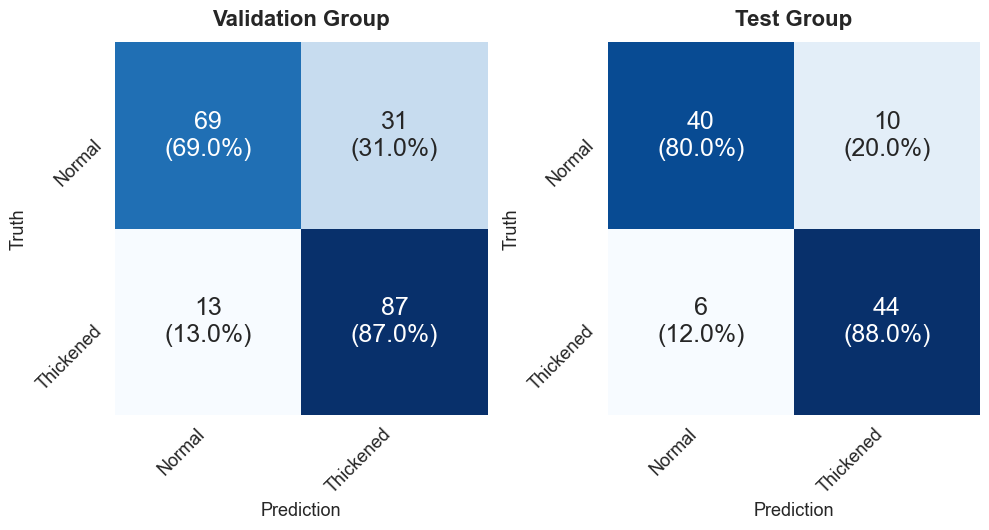

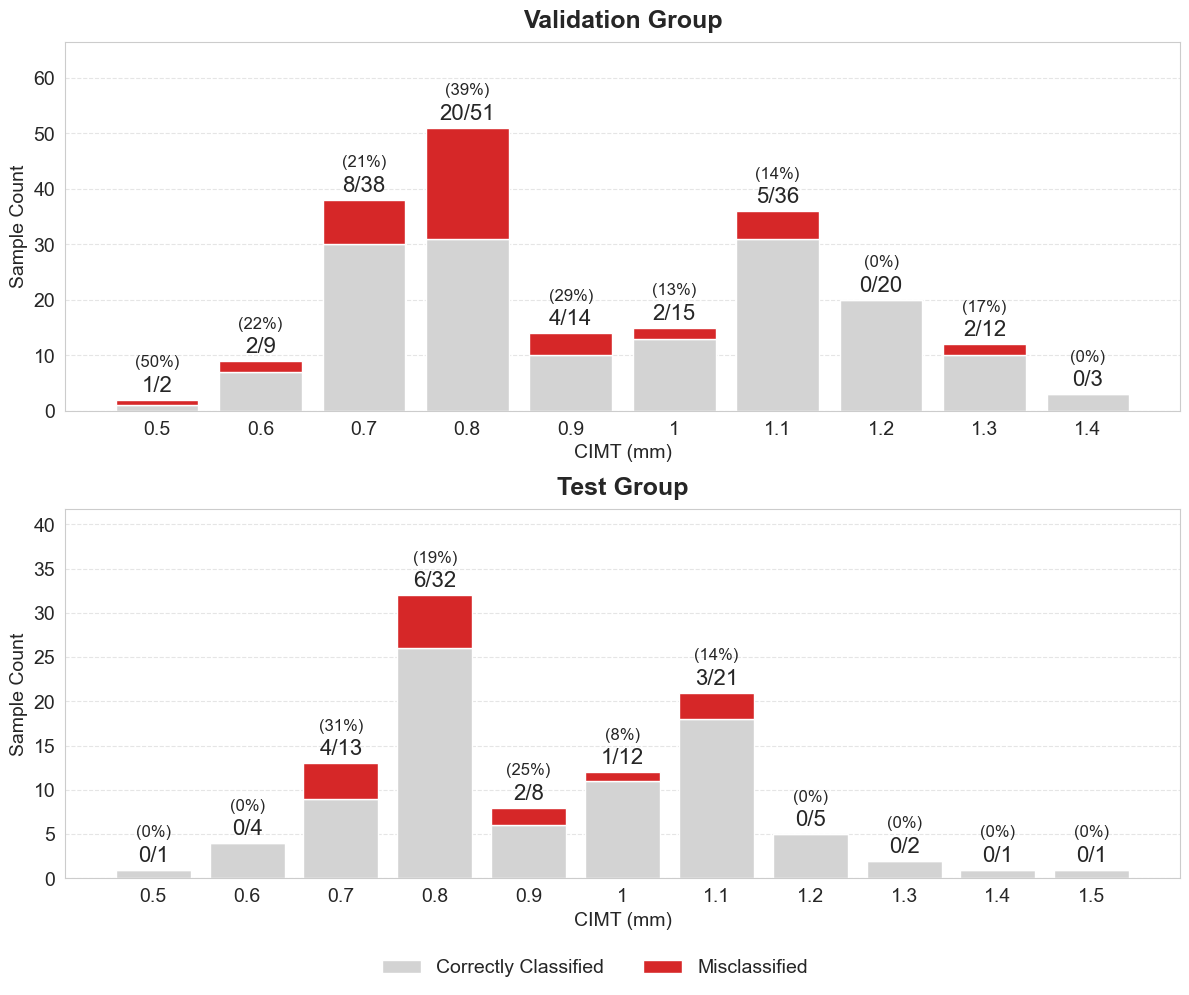

In [2]:
import torch
import timm
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM

def seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(3)

g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")
os.makedirs(result_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform, valid_transform = get_transform(380)

class_names = ['Normal', 'Thickened']

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model = model.to(device)
checkpoint = torch.load(os.path.join(chkpt_dir, "epoch9_validF1_0.7782.pth"))
model.load_state_dict(checkpoint["model_state"])
model.eval()


def evaluate_group(group_value):
    dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=group_value, transform=valid_transform)
    loader = DataLoader(
        dataset,
        batch_size=40,
        shuffle=False,
        num_workers=8,
        pin_memory=True,
        prefetch_factor=2,
        generator=g,
    )

    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for left_images, right_images, labels in loader:
            left_images = left_images.to(device, non_blocking=True)
            right_images = right_images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(left_images, right_images)
            _, preds = torch.max(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs[:, 1].cpu().numpy())

    ordered_rows = dataset.dataframe.loc[dataset.indices]
    thickness_values = ordered_rows["thickness"].tolist()
    assert len(thickness_values) == len(all_labels), (
        f"Mismatch: {len(thickness_values)} thickness values vs {len(all_labels)} predictions."
    )

    report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)
    auroc = roc_auc_score(all_labels, all_probs)
    auprc = average_precision_score(all_labels, all_probs)

    return {
        "preds": np.array(all_preds),
        "labels": np.array(all_labels),
        "probs": np.array(all_probs),
        "thickness": np.array(thickness_values),
        "report": report,
        "auroc": auroc,
        "auprc": auprc,
    }


valid_results = evaluate_group(group_value=2)
test_results = evaluate_group(group_value=3)

print("Validation classification report:", valid_results["report"])
print(f"Validation AU-ROC: {valid_results['auroc']:.4f}  AU-PRC: {valid_results['auprc']:.4f}")
print("Test classification report:", test_results["report"])
print(f"Test AU-ROC: {test_results['auroc']:.4f}  AU-PRC: {test_results['auprc']:.4f}")


def build_thickness_summary(labels, preds, thickness):
    df = pd.DataFrame({"thickness": thickness, "true_label": labels, "pred_label": preds})
    df["correct"] = df["true_label"] == df["pred_label"]
    summary = df.groupby("thickness", observed=True).agg(
        n_total=("correct", "count"),
        n_misclassified=("correct", lambda x: int((~x).sum()))
    ).reset_index()
    summary["n_correct"] = summary["n_total"] - summary["n_misclassified"]
    summary["pct_misclassified"] = np.where(
        summary["n_total"] > 0,
        summary["n_misclassified"] / summary["n_total"] * 100,
        0.0
    )
    return summary.sort_values("thickness").reset_index(drop=True)


valid_summary = build_thickness_summary(valid_results["labels"], valid_results["preds"], valid_results["thickness"])
test_summary = build_thickness_summary(test_results["labels"], test_results["preds"], test_results["thickness"])

valid_summary.to_csv(os.path.join(result_dir, "misclassification_by_thickness_valid.csv"), index=False)
test_summary.to_csv(os.path.join(result_dir, "misclassification_by_thickness_test.csv"), index=False)

# ------------------------------------------------------------------
# Two separate figures: (1) confusion matrices, (2) stacked bar charts
# ------------------------------------------------------------------

def plot_cm(ax, labels, preds, class_labels):
    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    annot = np.empty_like(cm).astype(object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)"

    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        ax=ax,
        square=True,
        annot_kws={"fontsize": 18},
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=13)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=45, ha="right", va="top", fontsize=13)

    ax.set_xlabel("Prediction", fontsize=13)
    ax.set_ylabel("Truth", fontsize=13)


def plot_thickness_bar(ax, summary, title=None, fontsize=14, label_fontsize=16, ytick_fontsize=14):
    x = np.arange(len(summary))
    ax.bar(x, summary["n_correct"], color="lightgray", label="Correctly Classified")
    ax.bar(x, summary["n_misclassified"], bottom=summary["n_correct"], color="#D62728", label="Misclassified")

    max_total = max(summary["n_total"])
    pct_fontsize = label_fontsize - 4  # smaller font for the percentage line

    for i, (n_total, n_mis, pct) in enumerate(zip(summary["n_total"], summary["n_misclassified"], summary["pct_misclassified"])):
        if n_total > 0:
            frac_label = f"{int(n_mis)}/{int(n_total)}"
            pct_label = f"({pct:.0f}%)"

            # Fraction line (main size), just above the bar — offset in points, not data units
            ax.annotate(frac_label, xy=(i, n_total), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=label_fontsize)
            # Percentage line (smaller), stacked above the fraction line
            ax.annotate(pct_label, xy=(i, n_total), xytext=(0, 3 + label_fontsize * 1.15),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=pct_fontsize)

    # Extra headroom above the tallest bar so labels aren't clipped by the axis.
    headroom = 0.16 + label_fontsize * 0.009
    ax.set_ylim(0, max_total * (1 + headroom))

    ax.set_xticks(x)
    n_labels = len(summary)
    step = max(1, n_labels // 30)
    thinned_labels = [f"{v:g}" if i % step == 0 else "" for i, v in enumerate(summary["thickness"])]
    ax.set_xticklabels(thinned_labels, rotation=0, ha="center", fontsize=14)

    ax.tick_params(axis="y", labelsize=ytick_fontsize)

    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.grid(axis="x", visible=False)

    ax.set_xlabel("CIMT (mm)", fontsize=14)
    ax.set_ylabel("Sample Count", fontsize=14)

    if title:
        ax.set_title(title, fontsize=fontsize, fontweight="bold", pad=10)

# ---- Figure 1: confusion matrices (side by side) ----
fig_cm, (ax_cm_valid, ax_cm_test) = plt.subplots(1, 2, figsize=(10, 6))

plot_cm(ax_cm_valid, valid_results["labels"], valid_results["preds"], class_names)
plot_cm(ax_cm_test, test_results["labels"], test_results["preds"], class_names)

ax_cm_valid.set_title("Validation Group", fontsize=16, fontweight="bold", pad=12)
ax_cm_test.set_title("Test Group", fontsize=16, fontweight="bold", pad=12)

fig_cm.tight_layout()
fig_cm.savefig(os.path.join(result_dir, "confusion_matrices97782.pdf"), bbox_inches="tight")

# ---- Figure 2: stacked bar charts (valid on top, test below) ----
fig_bar, (ax_bar_valid, ax_bar_test) = plt.subplots(2, 1, figsize=(12, 10))

plot_thickness_bar(ax_bar_valid, valid_summary, title="Validation Group", fontsize=18, label_fontsize=16, ytick_fontsize=14)
plot_thickness_bar(ax_bar_test, test_summary, title="Test Group", fontsize=18, label_fontsize=16, ytick_fontsize=14)

fig_bar.tight_layout(rect=[0, 0.05, 1, 1])  # leave room at bottom for the legend

legend_fontsize = 14
handles, legend_labels = ax_bar_valid.get_legend_handles_labels()
fig_bar.legend(handles, legend_labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0),
               frameon=False, fontsize=legend_fontsize)

fig_bar.savefig(os.path.join(result_dir, "misclassification_bars97782.pdf"), bbox_inches="tight")

plt.show()

In [1]:
import torch
import timm
import os
import random
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM


def seed_everything(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")
os.makedirs(result_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_, valid_transform = get_transform(380)

class_names = ['Normal', 'Thickened']

# ============================================================
# >>> TYPE THE 10 CHECKPOINT FILENAMES HERE <<<
# These are just the filenames (assumed to live inside chkpt_dir),
# e.g. "epoch24_validF1_0.7944_seed0.pth". Order doesn't matter.
# ============================================================
CHECKPOINT_FILES = [
    "epoch24_validF1_0.7944.pth",
    "epoch16_validF1_0.7900.pth",
    "epoch14_validF1_0.7899.pth",
    "epoch9_validF1_0.7782.pth",
    "epoch1_validF1_0.7750.pth",
    "epoch24_validF1_0.7650.pth",
    "epoch2_validF1_0.7528.pth",
    "epoch15_validF1_0.7897.pth",
    "epoch10_validF1_0.7463.pth",
    "epoch17_validF1_0.7995.pth",
]
# ============================================================


def build_model():
    base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
    backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
    model = Siamese_EfficientNetB4_CBAM(
        backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2
    )
    return model.to(device)


def evaluate_group(model, group_value):
    dataset = FundusDataset.from_json(
        json_dir=json_dir, img_dir=img_dir, group_value=group_value, transform=valid_transform
    )
    loader = DataLoader(
        dataset,
        batch_size=40,
        shuffle=False,
        num_workers=8,
        pin_memory=True,
        prefetch_factor=2,
        generator=g,
    )

    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for left_images, right_images, labels in loader:
            left_images = left_images.to(device, non_blocking=True)
            right_images = right_images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(left_images, right_images)
            _, preds = torch.max(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs[:, 1].cpu().numpy())

    report = classification_report(
        all_labels, all_preds, target_names=class_names, output_dict=True
    )
    auroc = roc_auc_score(all_labels, all_probs)
    auprc = average_precision_score(all_labels, all_probs)

    return {
        "f1_normal": report["Normal"]["f1-score"],
        "f1_thickened": report["Thickened"]["f1-score"],
        "macro_f1": report["macro avg"]["f1-score"],
        "auroc": auroc,
        "auprc": auprc,
    }


# ------------------------------------------------------------------
# Run all 10 checkpoints, collect metrics for validation + test
# ------------------------------------------------------------------
records = []

for ckpt_name in CHECKPOINT_FILES:
    ckpt_path = os.path.join(chkpt_dir, ckpt_name)
    print(f"\nEvaluating checkpoint: {ckpt_name}")

    seed_everything(3)  # keep dataloader/eval behavior identical across checkpoints
    model = build_model()
    checkpoint = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

    valid_metrics = evaluate_group(model, group_value=2)
    test_metrics = evaluate_group(model, group_value=3)

    records.append({
        "checkpoint": ckpt_name,
        "valid_f1_normal": valid_metrics["f1_normal"],
        "valid_f1_thickened": valid_metrics["f1_thickened"],
        "valid_macro_f1": valid_metrics["macro_f1"],
        "valid_auroc": valid_metrics["auroc"],
        "valid_auprc": valid_metrics["auprc"],
        "test_f1_normal": test_metrics["f1_normal"],
        "test_f1_thickened": test_metrics["f1_thickened"],
        "test_macro_f1": test_metrics["macro_f1"],
        "test_auroc": test_metrics["auroc"],
        "test_auprc": test_metrics["auprc"],
    })

    del model
    torch.cuda.empty_cache()

results_df = pd.DataFrame(records)
results_df.to_csv(os.path.join(result_dir, "multiseed_per_checkpoint_metrics.csv"), index=False)

# ------------------------------------------------------------------
# Average (and std) across the 10 checkpoints
# ------------------------------------------------------------------
metric_cols = [c for c in results_df.columns if c != "checkpoint"]
summary_df = pd.DataFrame({
    "mean": results_df[metric_cols].mean(),
    "std": results_df[metric_cols].std(),
})

summary_df.to_csv(os.path.join(result_dir, "multiseed_summary_metrics.csv"))

print("\n=== Per-checkpoint metrics ===")
print(results_df)

print("\n=== Mean +/- Std across 10 checkpoints ===")
print(summary_df)


Evaluating checkpoint: epoch24_validF1_0.7944.pth

Evaluating checkpoint: epoch16_validF1_0.7900.pth



Evaluating checkpoint: epoch14_validF1_0.7899.pth

Evaluating checkpoint: epoch9_validF1_0.7782.pth

Evaluating checkpoint: epoch1_validF1_0.7750.pth

Evaluating checkpoint: epoch24_validF1_0.7650.pth

Evaluating checkpoint: epoch2_validF1_0.7528.pth

Evaluating checkpoint: epoch15_validF1_0.7897.pth

Evaluating checkpoint: epoch10_validF1_0.7463.pth

Evaluating checkpoint: epoch17_validF1_0.7995.pth

=== Per-checkpoint metrics ===
                   checkpoint  valid_f1_normal  valid_f1_thickened  \
0  epoch24_validF1_0.7944.pth         0.783069            0.805687   
1  epoch16_validF1_0.7900.pth         0.790000            0.790000   
2  epoch14_validF1_0.7899.pth         0.785714            0.794118   
3   epoch9_validF1_0.7782.pth         0.758242            0.798165   
4   epoch1_validF1_0.7750.pth         0.776119            0.773869   
5  epoch24_validF1_0.7650.pth         0.766169            0.763819   
6   epoch2_validF1_0.7528.pth         0.729282            0.776256   
7  

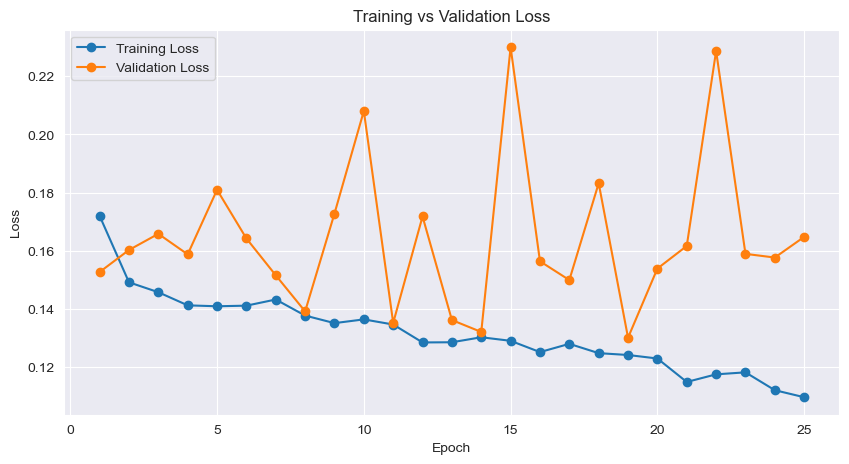

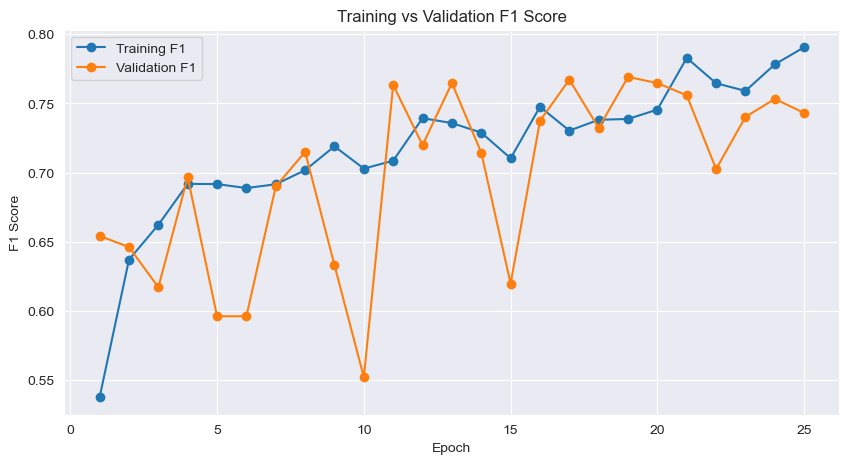

In [3]:
import matplotlib.pyplot as plt

epochs = range(1, len(training_record["train_loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, training_record["train_loss"], label="Training Loss", marker='o')
plt.plot(epochs, training_record["valid_loss"], label="Validation Loss", marker='o')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epochs, training_record["train_f1"], label="Training F1", marker='o')
plt.plot(epochs, training_record["valid_f1"], label="Validation F1", marker='o')
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Training vs Validation F1 Score")
plt.legend()
plt.grid(True)
plt.show()

{'Normal': {'precision': 0.8478260869565217, 'recall': 0.78, 'f1-score': 0.8125, 'support': 50.0}, 'Thickened': {'precision': 0.7962962962962963, 'recall': 0.86, 'f1-score': 0.8269230769230769, 'support': 50.0}, 'accuracy': 0.82, 'macro avg': {'precision': 0.822061191626409, 'recall': 0.8200000000000001, 'f1-score': 0.8197115384615384, 'support': 100.0}, 'weighted avg': {'precision': 0.822061191626409, 'recall': 0.82, 'f1-score': 0.8197115384615384, 'support': 100.0}}


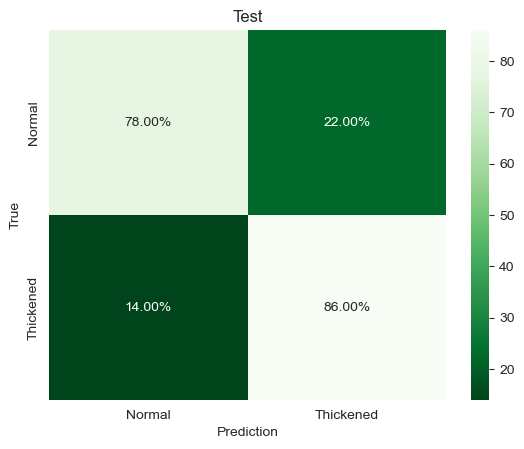

AU-ROC: 0.8564
AU-PRC: 0.8509


In [2]:
import torch
import timm
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, auc
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM

def seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(3)

g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform, valid_transform = get_transform(380)

valid_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=3, transform=valid_transform)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=40,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model = model.to(device)
checkpoint = torch.load(os.path.join(chkpt_dir, "epoch18_validF1_0.7950.pth"))
model.load_state_dict(checkpoint["model_state"])

model.eval()
total_valid_loss = 0.0
valid_corrects = 0
all_valid_preds = []
all_valid_labels = []
all_valid_probs = []

with torch.no_grad():
            for i, (left_images, right_images, labels) in enumerate(valid_loader):
                left_images = left_images.to(device, non_blocking=True)
                right_images = right_images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                outputs = model(left_images, right_images)
                _, preds = torch.max(outputs, dim=1)
                valid_corrects += torch.sum(preds == labels.data)
                all_valid_preds.extend(preds.cpu().numpy())
                all_valid_labels.extend(labels.cpu().numpy())
                probs = torch.softmax(outputs, dim=1) # (B,2)
                pos_scores = probs[:, 1] # probability of positive class (class index 1)
                all_valid_probs.extend(pos_scores.cpu().numpy())

class_names = ['Normal', 'Thickened']
report = classification_report(all_valid_labels, all_valid_preds, target_names=class_names, output_dict=True)
print(report)
# report_df = pd.DataFrame(report).transpose()
# report_df.to_csv(os.path.join(result_dir, "report_unfreezing1_test.csv"))

cm = confusion_matrix(all_valid_labels, all_valid_preds)
cm_percentage = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
labels = np.array([[f"{value:.2f}%" for value in row] for row in cm_percentage])
sns.heatmap(cm_percentage, annot=labels, fmt="", cmap="Greens_r", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediction")
plt.ylabel("True")
plt.title("Test")
# plt.savefig(os.path.join(result_dir, "confusion_matrix_unfreezing1_test.png"), dpi=300)
plt.show()

# AU-ROC and AU-PRC computation
y_true = np.array(all_valid_labels)
y_scores = np.array(all_valid_probs)

unique_classes = np.unique(y_true)
auroc = roc_auc_score(y_true, y_scores)
auprc = average_precision_score(y_true, y_scores)  # average precision == area under PR curve (AP)

print(f"AU-ROC: {auroc:.4f}")
print(f"AU-PRC: {auprc:.4f}")